# Process the goggles-monocular session

Builds the `MonocularDevice` (eye-conditioned), runs `SessionAnalyzer.analyze_session_stats`,
and saves `{session_name}_dataframe.pkl` next to the session data. That pkl is what
`monocular-disparity-distance-comparison.ipynb` reads for this experiment via
`CrossExperimentAnalysis.from_devices(R, M, D)`.

Run this in its own kernel with **only** `disparity-analysis` on `sys.path`.

In [1]:
import sys, os
import pandas as pd

base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

from src.data.MonocularDevice import MonocularDevice
from src.analysis.CellAnalysis import SessionAnalyzer

%load_ext autoreload
%autoreload 2
%matplotlib widget

In [2]:
mouse, date, experiment = "SAM047", "260928", "monocular"
M = MonocularDevice(mouse_name=mouse, record_date=date, experiment_name=experiment, on_length=60)
print("session:", M.session_name, "| eyes:", M.present_eyes, "| cells:", len(M.suite2p_id))

Directory results already exists
session: 260928_SAM047_monocular | eyes: ['right', 'left'] | cells: 1239


In [4]:
# load cached stats if present, else compute once (slow) and save the pkl the
# comparison notebook reads
pkl_path = os.path.join(M.data_dir, f"{M.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = SessionAnalyzer(M).analyze_session_stats(n_iterations=200)
    SessionAnalyzer(M).save_dataframe(stats_df)   # -> pkl_path
stats_df.head()

Saved DataFrame to: D:/data-distance-coding-project/processed-data\260928_SAM047_monocular\260928_SAM047_monocular_dataframe.pkl


,cell,session_name,right_reliable,right_mean_corr,right_rf,right_rf_value,right_px,left_reliable,left_mean_corr,left_rf,left_rf_value,left_px,ODI
0,0,260928_SAM047_monocular,False,0.498797,51,0.160499,103.728814,False,0.120153,54,0.433148,-10.169492,-0.459278
1,1,260928_SAM047_monocular,False,0.452163,0,0.272512,0.000000,False,-0.140824,2,0.377294,-115.932203,-0.161251
2,2,260928_SAM047_monocular,False,0.234299,22,0.292643,44.745763,False,-0.163964,15,0.444549,-89.491525,-0.206060
3,3,260928_SAM047_monocular,False,0.300162,0,0.292837,0.000000,False,-0.328844,52,0.176491,-14.237288,0.247898
4,4,260928_SAM047_monocular,False,0.215251,32,0.052139,65.084746,False,0.401950,7,0.329605,-105.762712,-0.726839


In [5]:
# --- save the standard report for this session ---
from src.viz.SessionVisualizer import SessionVisualizer

sv = SessionVisualizer(M, stats_df=stats_df, corr_threshold=0.7)

# summary/ (summary + plots + map) and one folder per group of reliable cells
# plot_cells=False -> summary folder only, skips the slow per-cell figures
sets = sv.save_report(plot_cells=True)

reliable_cells = sorted(sets["either"])    # reliable in left OR right eye
print(f"{len(reliable_cells)} cells reliable in at least one eye")

 Session: 260928_SAM047_monocular
 Eyes shown: right, left
 Total cells: 1239
 mean_corr floor: 0.7
--------------------------------------------------
 Reliable (either eye) :  270  ( 21.8% of all cells)
--------------------------------------------------
 Among those 270 reliable cells:
 Right eye only        :  263  ( 97.4%)
 Left eye only         :    5  (  1.9%)
 Both eyes             :    2  (  0.7%)
Saved summary to: D:/data-distance-coding-project/processed-data\260928_SAM047_monocular\results\summary
Saved 263 figures to: D:/data-distance-coding-project/processed-data\260928_SAM047_monocular\results\right_only
Saved 5 figures to: D:/data-distance-coding-project/processed-data\260928_SAM047_monocular\results\left_only
Saved 2 figures to: D:/data-distance-coding-project/processed-data\260928_SAM047_monocular\results\both
Report saved under: D:/data-distance-coding-project/processed-data\260928_SAM047_monocular\results
270 cells reliable in at least one eye


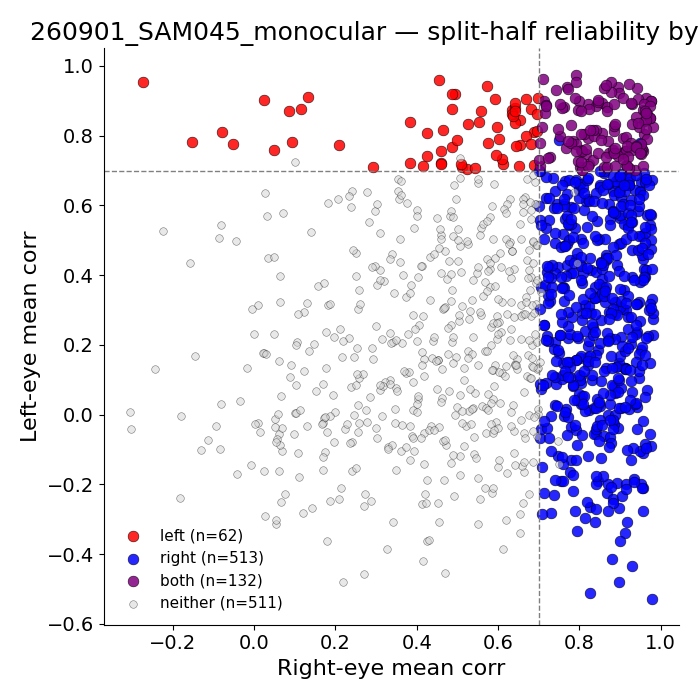

In [45]:
fig = sv.plot_corr_scatter()

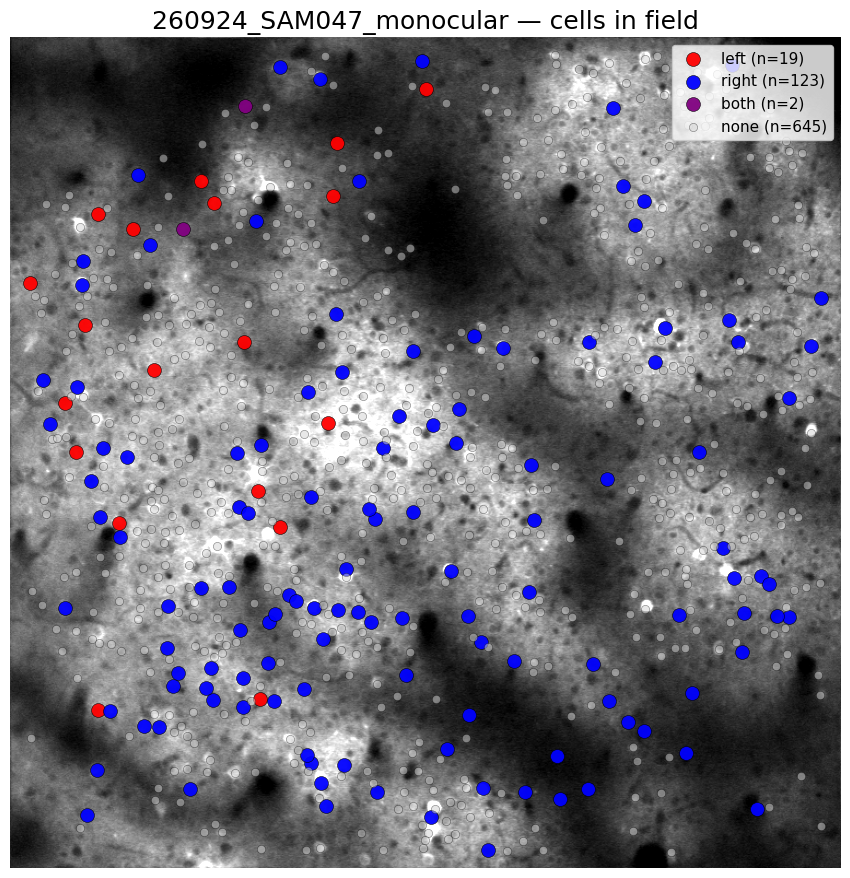

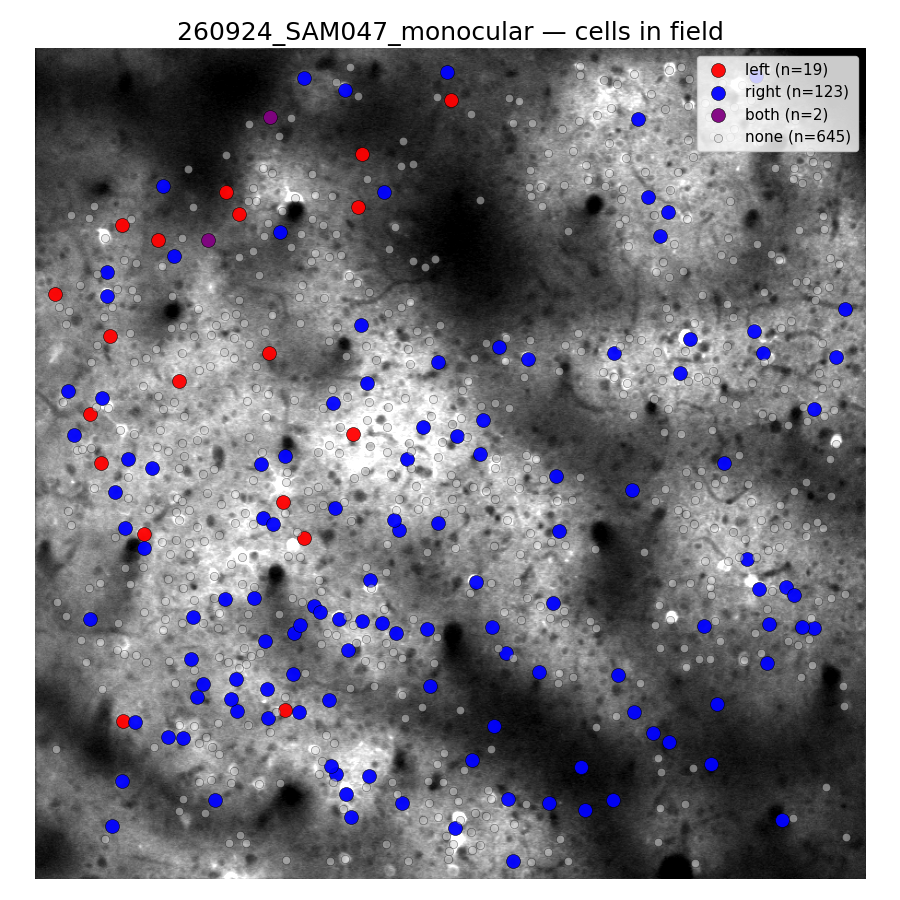

In [30]:
sv.plot_location_map(corr_threshold=0.75, cell_size=100)

C:\Users\acostamendoza\projects\distance-project\disparity-analysis\src\viz\SessionVisualizer.py:558: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


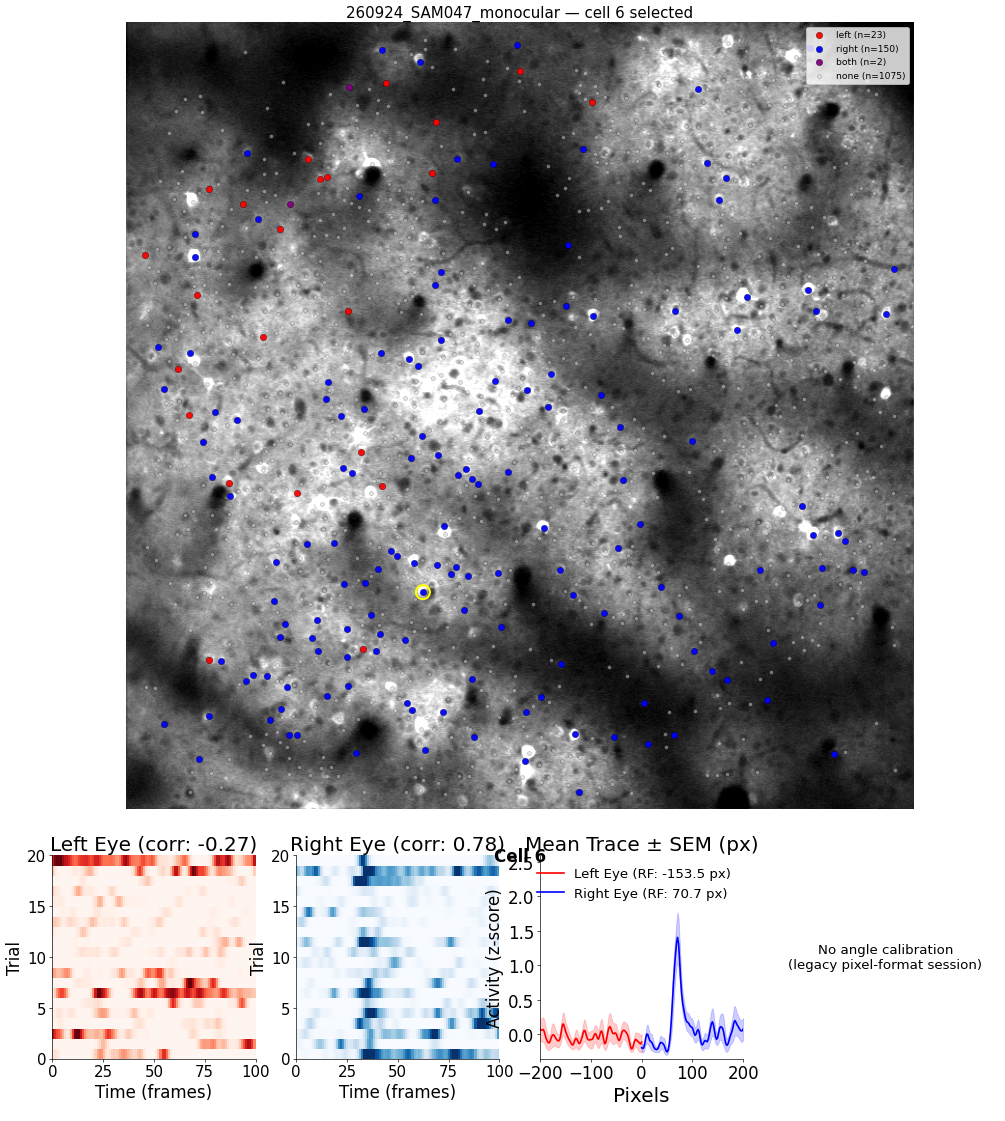

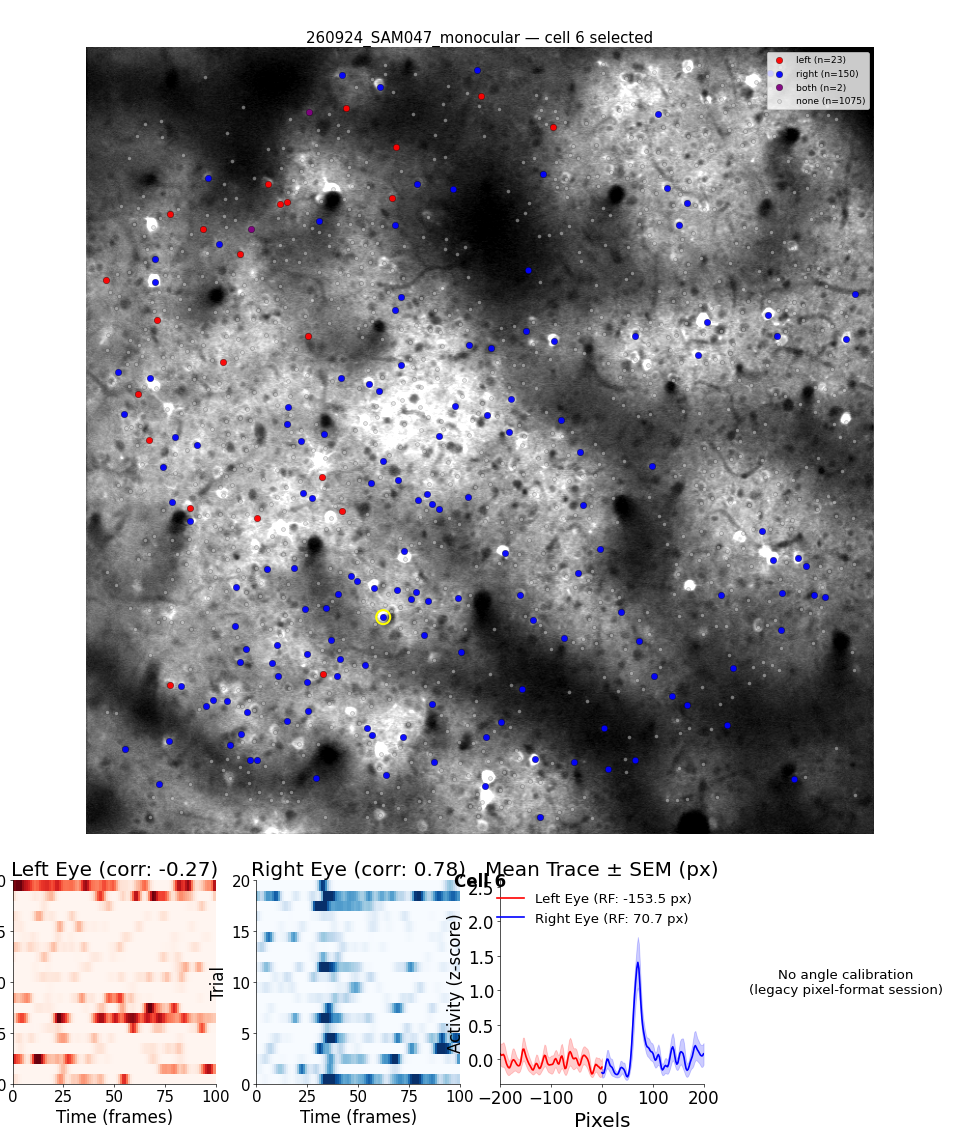

In [24]:
from src.viz.SessionVisualizer import SessionVisualizer
from src.viz.CellVisualizer import CellVisualizer
from src.viz.InteractiveCellExplorer import InteractiveCellExplorer

sv = SessionVisualizer(M, stats_df=stats_df, corr_threshold=0.75)
cv = CellVisualizer(M, stats_df=stats_df)

explorer = InteractiveCellExplorer(sv, cv)
explorer.show()   # top: location map; bottom: make_comparison_plot for a starting cell